# Partie 5 : Implémentation du réseau de neurones

Chargement des données en cours...
Dimensions de X : (1566, 4098)
Dimensions de y : (1566,)
------------------------------
--- Échantillon n°0 ---
Label (Étiquette) : 0
Nombre de motifs détectés : 1.0
Écart-type (Contraste) : 55.785528191060045


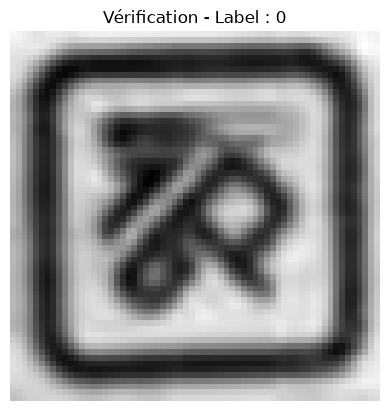

In [13]:
import numpy as np
import pickle
import matplotlib.pyplot as plt

# 1. Chargement des données
print("Chargement des données en cours...")
with open("X1.pickle", "rb") as f:
    X = pickle.load(f)

with open("y1.pickle", "rb") as f:
    y = pickle.load(f)

# 2. Vérification globale
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("-" * 30)

# 3. Vérification de l'intégrité (séparation des pixels et des features)
index_test = 0  # On teste le premier élément

# X contient 4098 valeurs : les 4096 premières sont les pixels, les 2 dernières sont nos features
pixels = X[index_test][:-2]
extra_features = X[index_test][-2:]
label = y[index_test]

# On reforme l'image en 64x64 pour s'assurer que l'ordre des pixels est bon
image_reconstruite = pixels.reshape((64, 64))

print(f"--- Échantillon n°{index_test} ---")
print(f"Label (Étiquette) : {label}")
print(f"Nombre de motifs détectés : {extra_features[0]}")
print(f"Écart-type (Contraste) : {extra_features[1]}")

# 4. Affichage visuel
plt.imshow(image_reconstruite, cmap="gray")
plt.title(f"Vérification - Label : {label}")
plt.axis("off")
plt.show()

### 5.1 : Préparation des données et initialisation du réseau
**Objectifs :**
1. **Normalisation & Standardisation** : Mettre les pixels à l'échelle [0, 1] et standardiser nos 2 caractéristiques (moyenne=0, variance=1) pour garantir la stabilité de l'apprentissage.
2. **Encodage One-Hot** : Convertir les étiquettes en vecteurs binaires (pour la prédiction de probabilités).
3. **Architecture** : Création de la classe `ReseauNeurones` et initialisation des matrices de poids ($W$) via la méthode de *He* (optimale pour éviter la disparition du gradient) et des biais ($b$) à zéro.

In [14]:
import numpy as np

# --- 1. PRÉPARATION DES DONNÉES ---

# Séparation des pixels et des caractéristiques supplémentaires
X_pixels = X[:, :-2]
X_features = X[:, -2:]

# Normalisation des pixels (mise à l'échelle 0 à 1)
X_pixels_norm = X_pixels / 255.0

# Standardisation des features (Z-score : moyenne 0, variance 1)
X_features_mean = np.mean(X_features, axis=0)
X_features_std = np.std(X_features, axis=0)
X_features_norm = (X_features - X_features_mean) / (X_features_std + 1e-8)

# Recombinaison de la matrice X d'entrée
X_ready = np.hstack((X_pixels_norm, X_features_norm))

# Remappage des étiquettes (ex: 0, 3, 15 -> 0, 1, ..., 7)
classes_uniques = np.unique(y)
num_classes = len(classes_uniques)
y_mapped = np.array([np.where(classes_uniques == val)[0][0] for val in y])

# One-Hot Encoding pour y
y_one_hot = np.zeros((y_mapped.size, num_classes))
y_one_hot[np.arange(y_mapped.size), y_mapped] = 1

print("Dimensions de X_ready :", X_ready.shape)
print("Dimensions de y_one_hot :", y_one_hot.shape)


# --- 2. ARCHITECTURE DU RÉSEAU FROM SCRATCH ---

class ReseauNeurones:
    def __init__(self, input_size, hidden_size, output_size):
        # Initialisation de He (recommandée pour la plupart des réseaux)
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2. / input_size)
        self.b1 = np.zeros((1, hidden_size))
        
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2. / hidden_size)
        self.b2 = np.zeros((1, output_size))
        
        print(f"Réseau initialisé : {input_size} entrées -> {hidden_size} neurones cachés -> {output_size} sorties")

# Instanciation du modèle
nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes)

Dimensions de X_ready : (1566, 4098)
Dimensions de y_one_hot : (1566, 8)
Réseau initialisé : 4098 entrées -> 128 neurones cachés -> 8 sorties


### 5.2 : Propagation avant (Forward Pass) et fonctions d'activation
**Objectifs :**
1. **Fonctions d'activation :** Ajout des fonctions mathématiques `ReLU`, `Sigmoïde` et `Tanh` pour la couche cachée, avec un système simple pour passer de l'une à l'autre.
2. **Softmax :** Ajout de la fonction Softmax sur la couche de sortie pour transformer nos valeurs brutes (logits) en probabilités (somme = 1) pour nos 8 classes.
3. **Propagation avant (`forward`) :** Calcul matriciel ($Z = X \cdot W + b$) suivi de l'activation ($A = f(Z)$) de la couche d'entrée jusqu'à la sortie. Mise en cache des résultats `Z` et `A` pour la future rétropropagation.

In [3]:
import numpy as np

class ReseauNeurones:
    def __init__(self, input_size, hidden_size, output_size, activation_par_defaut='relu'):
        # Initialisation des poids (He) et biais
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2. / input_size)
        self.b1 = np.zeros((1, hidden_size))
        
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2. / hidden_size)
        self.b2 = np.zeros((1, output_size))
        
        self.activation_par_defaut = activation_par_defaut
        print(f"Réseau initialisé : {input_size} entrées -> {hidden_size} neurones ({self.activation_par_defaut}) -> {output_size} sorties")

    # --- Fonctions d'activation pour la couche cachée ---
    
    def relu(self, Z):
        return np.maximum(0, Z)

    def sigmoid(self, Z):
        # np.clip évite le dépassement de capacité (overflow) avec np.exp
        Z_clipped = np.clip(Z, -500, 500)
        return 1 / (1 + np.exp(-Z_clipped))

    def tanh(self, Z):
        return np.tanh(Z)

    # --- Fonction d'activation pour la couche de sortie (classification multiclasse) ---
    
    def softmax(self, Z):
        # Stabilité numérique : on soustrait le maximum de chaque ligne avant l'exponentielle
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    # --- Propagation Avant ---
    
    def forward(self, X, activation=None):
        if activation is None:
            activation = self.activation_par_defaut
            
        # Couche cachée
        self.Z1 = np.dot(X, self.W1) + self.b1
        
        if activation == 'relu':
            self.A1 = self.relu(self.Z1)
        elif activation == 'sigmoid':
            self.A1 = self.sigmoid(self.Z1)
        elif activation == 'tanh':
            self.A1 = self.tanh(self.Z1)
        else:
            raise ValueError(f"Activation '{activation}' non reconnue.")
            
        # Couche de sortie
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self.softmax(self.Z2)
        
        return self.A2

# Instanciation du modèle mis à jour
nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# Test de la propagation avant
predictions = nn.forward(X_ready)

print("Dimensions des prédictions (A2) :", predictions.shape)
print("Prédictions pour la première image (probabilités) :")
print(np.round(predictions[0], 4))
print("Somme des probabilités (doit être 1.0) :", np.sum(predictions[0]))

# Pour tester une autre activation en une ligne :
# predictions_tanh = nn.forward(X_ready, activation='tanh')

Réseau initialisé : 4098 entrées -> 128 neurones (relu) -> 8 sorties
Dimensions des prédictions (A2) : (504, 8)
Prédictions pour la première image (probabilités) :
[0.0389 0.0439 0.3229 0.1006 0.1228 0.0847 0.1374 0.1488]
Somme des probabilités (doit être 1.0) : 1.0


### 5.3 : Calcul de l'erreur (Loss), rétropropagation (Backward Pass) et descente de gradient
**Objectifs :**
1. **Perte par Entropie Croisée (Categorical Cross-Entropy) :** Mesurer l'écart entre nos probabilités prédites ($A_2$) et les vraies étiquettes encodées en One-Hot ($Y$).
2. **Dérivées des activations :** Implémenter les dérivées $\text{ReLU}'$, $\text{Sigmoïde}'$ et $\text{Tanh}'$ indispensables à la règle de dérivation en chaîne (*Chain Rule*).
3. **Rétropropagation (`backward`) :** Calculer les gradients de l'erreur par rapport à chaque poids et biais ($\frac{\partial L}{\partial W_2}, \frac{\partial L}{\partial b_2}, \frac{\partial L}{\partial W_1}, \frac{\partial L}{\partial b_1}$).
4. **Mise à jour (`update_params`) :** Ajuster les poids avec la descente de gradient selon un taux d'apprentissage (*learning rate* $\alpha$).

In [15]:
import numpy as np

class ReseauNeurones:
    def __init__(self, input_size, hidden_size, output_size, activation_par_defaut='relu'):
        # Initialisation de He
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2. / input_size)
        self.b1 = np.zeros((1, hidden_size))
        
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2. / hidden_size)
        self.b2 = np.zeros((1, output_size))
        
        self.activation_par_defaut = activation_par_defaut

    # --- 1. FONCTIONS D'ACTIVATION ET LEURS DÉRIVÉES ---
    
    def relu(self, Z):
        return np.maximum(0, Z)

    def relu_derivative(self, Z):
        return (Z > 0).astype(float)

    def sigmoid(self, Z):
        Z_clipped = np.clip(Z, -500, 500)
        return 1 / (1 + np.exp(-Z_clipped))

    def sigmoid_derivative(self, A):
        # A est déjà la valeur activée sigmoid(Z)
        return A * (1.0 - A)

    def tanh(self, Z):
        return np.tanh(Z)

    def tanh_derivative(self, A):
        # A est déjà la valeur activée tanh(Z)
        return 1.0 - np.square(A)

    def softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    # --- 2. CALCUL DE LA PERTE (LOSS) ---
    
    def compute_loss(self, y_true, y_pred):
        m = y_true.shape[0]
        # Évite log(0) grâce à un petit epsilon
        y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
        loss = -np.sum(y_true * np.log(y_pred_clipped)) / m
        return loss

    # --- 3. PROPAGATION AVANT ---
    
    def forward(self, X, activation=None):
        if activation is None:
            activation = self.activation_par_defaut
            
        self.Z1 = np.dot(X, self.W1) + self.b1
        
        if activation == 'relu':
            self.A1 = self.relu(self.Z1)
        elif activation == 'sigmoid':
            self.A1 = self.sigmoid(self.Z1)
        elif activation == 'tanh':
            self.A1 = self.tanh(self.Z1)
        else:
            raise ValueError(f"Activation '{activation}' non reconnue.")
            
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self.softmax(self.Z2)
        
        return self.A2

    # --- 4. RÉTROPROPAGATION (BACKWARD PASS) ---
    
    def backward(self, X, y_true, activation=None):
        if activation is None:
            activation = self.activation_par_defaut

        m = X.shape[0]
        
        # 1. Gradient de la couche de sortie (Combinaison Softmax + Cross-Entropy)
        dZ2 = self.A2 - y_true
        self.dW2 = np.dot(self.A1.T, dZ2) / m
        self.db2 = np.sum(dZ2, axis=0, keepdims=True) / m
        
        # 2. Propagation vers la couche cachée
        dA1 = np.dot(dZ2, self.W2.T)
        
        if activation == 'relu':
            dZ1 = dA1 * self.relu_derivative(self.Z1)
        elif activation == 'sigmoid':
            dZ1 = dA1 * self.sigmoid_derivative(self.A1)
        elif activation == 'tanh':
            dZ1 = dA1 * self.tanh_derivative(self.A1)
            
        self.dW1 = np.dot(X.T, dZ1) / m
        self.db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    # --- 5. MISE À JOUR DES POIDS ---
    
    def update_params(self, learning_rate=0.01):
        self.W1 -= learning_rate * self.dW1
        self.b1 -= learning_rate * self.db1
        self.W2 -= learning_rate * self.dW2
        self.b2 -= learning_rate * self.db2


# --- TEST D'UNE ÉTAPE D'ENTRAÎNEMENT ---

nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# 1. Avant entraînement
y_pred_init = nn.forward(X_ready)
loss_initiale = nn.compute_loss(y_one_hot, y_pred_init)
print(f"Perte initiale (avant apprentissage) : {loss_initiale:.4f}")

# 2. Un pas de rétropropagation et mise à jour
nn.backward(X_ready, y_one_hot)
nn.update_params(learning_rate=0.1)

# 3. Après 1 mise à jour
y_pred_apres = nn.forward(X_ready)
loss_apres = nn.compute_loss(y_one_hot, y_pred_apres)
print(f"Perte après 1 étape de mise à jour : {loss_apres:.4f}")

Perte initiale (avant apprentissage) : 2.2998
Perte après 1 étape de mise à jour : 3.3391


### 5.4 : Boucle d'entraînement (Epochs) et courbes d'apprentissage
**Objectifs :**
1. **Automatisation :** Répéter les étapes de propagation avant, de calcul de l'erreur, de rétropropagation et de mise à jour des poids sur plusieurs itérations (époques).
2. **Évaluation de la Précision (Accuracy) :** Comparer les prédictions finales (la probabilité maximale) avec les véritables étiquettes pour obtenir un pourcentage de réussite.
3. **Visualisation :** Tracer les courbes de la Loss et de l'Accuracy avec Matplotlib pour vérifier que le réseau converge bien sans osciller, signe d'un bon taux d'apprentissage.

Réseau initialisé : 4098 entrées -> 128 neurones (relu) -> 8 sorties
Début de l'entraînement...
------------------------------
Epoch   0/200 - Loss: 2.3027 - Accuracy: 8.73%
Epoch  20/200 - Loss: 1.6698 - Accuracy: 25.20%
Epoch  40/200 - Loss: 1.4628 - Accuracy: 45.44%
Epoch  60/200 - Loss: 1.0739 - Accuracy: 64.88%
Epoch  80/200 - Loss: 0.8214 - Accuracy: 73.61%
Epoch 100/200 - Loss: 0.8435 - Accuracy: 74.40%
Epoch 120/200 - Loss: 0.5046 - Accuracy: 87.90%
Epoch 140/200 - Loss: 0.8225 - Accuracy: 72.82%
Epoch 160/200 - Loss: 0.3772 - Accuracy: 90.08%
Epoch 180/200 - Loss: 0.3286 - Accuracy: 91.87%
Epoch 199/200 - Loss: 0.3264 - Accuracy: 90.08%
------------------------------
Entraînement terminé !


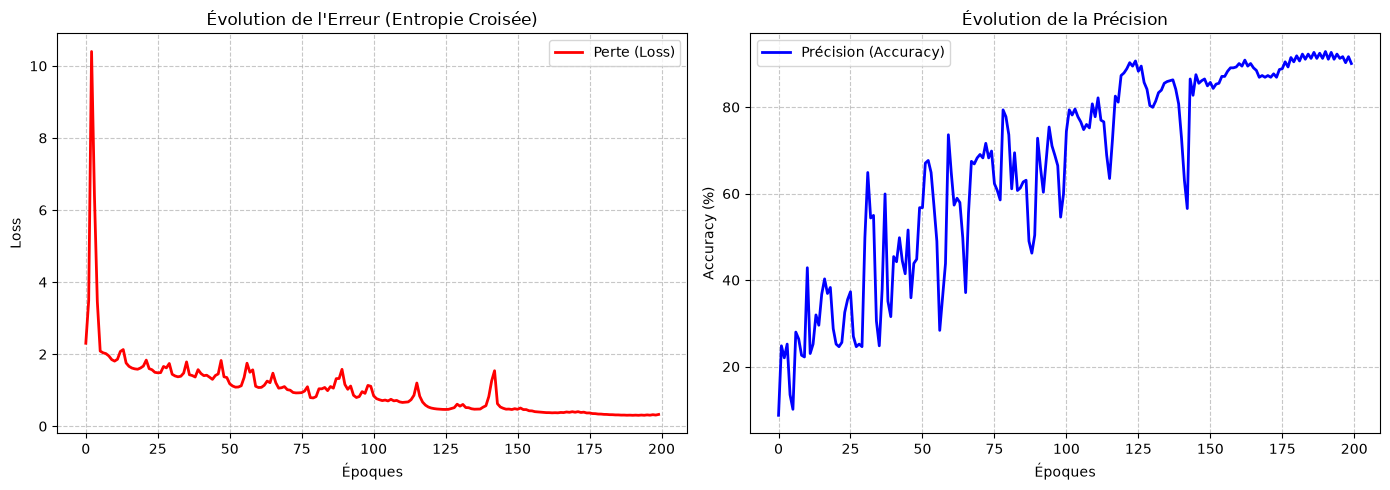

In [5]:
import matplotlib.pyplot as plt

# On ré-instancie le modèle pour repartir de zéro avec des poids frais
nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# --- HYPERPARAMÈTRES ---
epochs = 200            # Nombre de passages complets sur les données
learning_rate = 0.05    # Taille des pas de mise à jour des poids

# Listes pour stocker l'historique et tracer les courbes
historique_loss = []
historique_accuracy = []

print("Début de l'entraînement...\n" + "-"*30)

for epoch in range(epochs):
    # 1. Forward Pass (Propagation avant)
    y_pred = nn.forward(X_ready)
    
    # 2. Calcul de la Loss
    loss = nn.compute_loss(y_one_hot, y_pred)
    historique_loss.append(loss)
    
    # 3. Calcul de la Précision (Accuracy)
    # np.argmax retourne l'indice de la probabilité la plus haute (notre prédiction finale)
    predictions_classes = np.argmax(y_pred, axis=1)
    vraies_classes = np.argmax(y_one_hot, axis=1)
    accuracy = np.mean(predictions_classes == vraies_classes) * 100
    historique_accuracy.append(accuracy)
    
    # 4. Backward Pass (Rétropropagation) et Mise à jour
    nn.backward(X_ready, y_one_hot)
    nn.update_params(learning_rate)
    
    # Affichage des performances tous les 20 epochs
    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:3d}/{epochs} - Loss: {loss:.4f} - Accuracy: {accuracy:.2f}%")

print("-" * 30 + "\nEntraînement terminé !")

# --- TRACÉ DES COURBES D'APPRENTISSAGE ---

plt.figure(figsize=(14, 5))

# Courbe de la Loss
plt.subplot(1, 2, 1)
plt.plot(historique_loss, label='Perte (Loss)', color='red', linewidth=2)
plt.title('Évolution de l\'Erreur (Entropie Croisée)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Courbe de l'Accuracy
plt.subplot(1, 2, 2)
plt.plot(historique_accuracy, label='Précision (Accuracy)', color='blue', linewidth=2)
plt.title('Évolution de la Précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()

### 5.5 : Ajustement du taux d'apprentissage
**Observations :** Les courbes de Loss et d'Accuracy du premier entraînement présentaient de fortes oscillations (dents de scie). Cela indique un "overshooting" : le taux d'apprentissage était trop élevé, forçant le modèle à rebondir autour du minimum local.
**Action :** Réduction du taux d'apprentissage (`learning_rate`) pour lisser la descente de gradient, et augmentation du nombre d'époques (`epochs`) pour compenser la lenteur de la convergence.

Réseau initialisé : 4098 entrées -> 128 neurones (relu) -> 8 sorties
Début de l'entraînement...
------------------------------
Epoch   0/500 - Loss: 2.2975 - Accuracy: 7.34%
Epoch  20/500 - Loss: 1.4281 - Accuracy: 57.94%
Epoch  40/500 - Loss: 1.2245 - Accuracy: 70.63%
Epoch  60/500 - Loss: 1.0761 - Accuracy: 73.21%
Epoch  80/500 - Loss: 0.9615 - Accuracy: 76.59%
Epoch 100/500 - Loss: 0.8693 - Accuracy: 77.98%
Epoch 120/500 - Loss: 0.7934 - Accuracy: 79.17%
Epoch 140/500 - Loss: 0.7314 - Accuracy: 83.53%
Epoch 160/500 - Loss: 0.6794 - Accuracy: 85.32%
Epoch 180/500 - Loss: 0.6352 - Accuracy: 86.51%
Epoch 200/500 - Loss: 0.5972 - Accuracy: 86.90%
Epoch 220/500 - Loss: 0.5641 - Accuracy: 87.10%
Epoch 240/500 - Loss: 0.5349 - Accuracy: 87.50%
Epoch 260/500 - Loss: 0.5087 - Accuracy: 88.10%
Epoch 280/500 - Loss: 0.4855 - Accuracy: 88.29%
Epoch 300/500 - Loss: 0.4648 - Accuracy: 88.49%
Epoch 320/500 - Loss: 0.4462 - Accuracy: 89.29%
Epoch 340/500 - Loss: 0.4293 - Accuracy: 89.68%
Epoch 360/

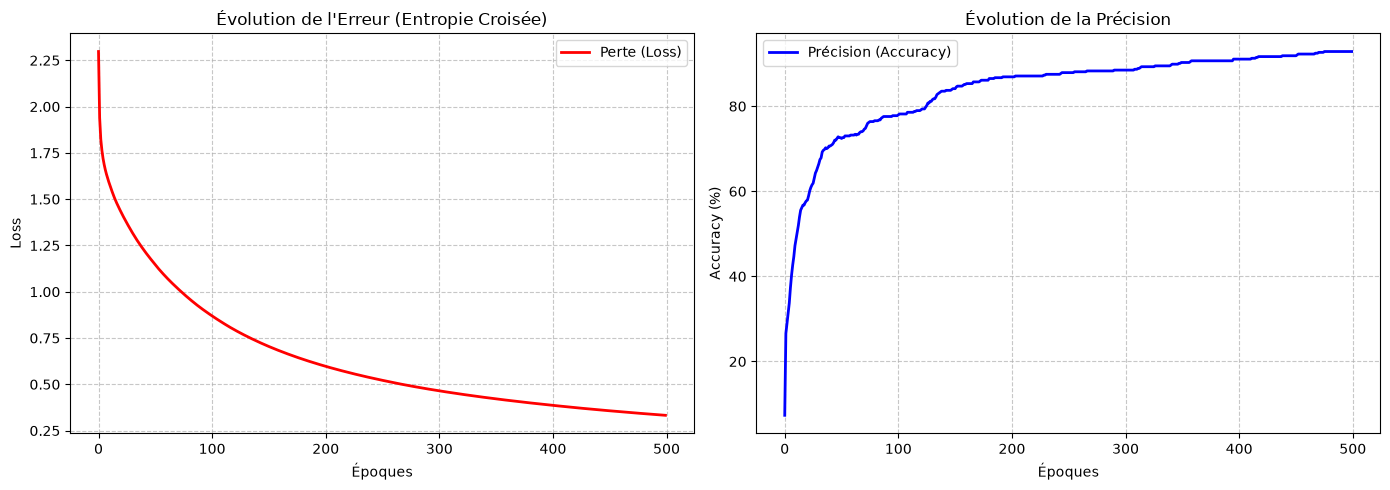

In [6]:
import matplotlib.pyplot as plt

# On ré-instancie le modèle pour repartir de zéro avec des poids frais
nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# --- HYPERPARAMÈTRES ---
epochs = 500            # Nombre de passages complets sur les données
learning_rate = 0.005    # Taille des pas de mise à jour des poids

# Listes pour stocker l'historique et tracer les courbes
historique_loss = []
historique_accuracy = []

print("Début de l'entraînement...\n" + "-"*30)

for epoch in range(epochs):
    # 1. Forward Pass (Propagation avant)
    y_pred = nn.forward(X_ready)
    
    # 2. Calcul de la Loss
    loss = nn.compute_loss(y_one_hot, y_pred)
    historique_loss.append(loss)
    
    # 3. Calcul de la Précision (Accuracy)
    # np.argmax retourne l'indice de la probabilité la plus haute (notre prédiction finale)
    predictions_classes = np.argmax(y_pred, axis=1)
    vraies_classes = np.argmax(y_one_hot, axis=1)
    accuracy = np.mean(predictions_classes == vraies_classes) * 100
    historique_accuracy.append(accuracy)
    
    # 4. Backward Pass (Rétropropagation) et Mise à jour
    nn.backward(X_ready, y_one_hot)
    nn.update_params(learning_rate)
    
    # Affichage des performances tous les 20 epochs
    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:3d}/{epochs} - Loss: {loss:.4f} - Accuracy: {accuracy:.2f}%")

print("-" * 30 + "\nEntraînement terminé !")

# --- TRACÉ DES COURBES D'APPRENTISSAGE ---

plt.figure(figsize=(14, 5))

# Courbe de la Loss
plt.subplot(1, 2, 1)
plt.plot(historique_loss, label='Perte (Loss)', color='red', linewidth=2)
plt.title('Évolution de l\'Erreur (Entropie Croisée)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Courbe de l'Accuracy
plt.subplot(1, 2, 2)
plt.plot(historique_accuracy, label='Précision (Accuracy)', color='blue', linewidth=2)
plt.title('Évolution de la Précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()

# Partie 6 : Évaluation du modèle

### 6.1 : Validation croisée à 5 plis

**Méthode :** validation croisée stratifiée à 5 plis sur l'EnsembleB (1 514 images, 8 classes). Chaque image est testée une fois, ce qui est plus fiable qu'un seul découpage, et les proportions des classes sont conservées.

**Hyperparamètres :** dans chaque pli, 12 configurations sont comparées sur 20 % des données d'entraînement (64 ou 128 neurones, taux de 0,005 à 0,02, 400 ou 800 époques). Le plus souvent retenus : 128 neurones, taux de 0,02 et 800 époques, avec ReLU pour limiter la disparition du gradient.

**Résultats :** exactitude de 96,6 % et F1 macro de 0,964.

In [16]:
import time
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

NOMS = ["Cercle2", "Cercle5", "Diamant2", "Diamant5", "Hexagone2", "Hexagone5", "Triangle2", "Triangle5"]

_, indices_uniques = np.unique(X, axis=0, return_index=True)
indices_uniques = np.sort(indices_uniques)

X_eval = X[indices_uniques]
y_sans_doublons = y[indices_uniques]
_, y_eval = np.unique(y_sans_doublons, return_inverse=True)

images_par_classe = np.bincount(y_eval).tolist()
print(X_eval.shape, dict(zip(NOMS, images_par_classe)))

(1514, 4098) {'Cercle2': 189, 'Cercle5': 132, 'Diamant2': 284, 'Diamant5': 159, 'Hexagone2': 270, 'Hexagone5': 150, 'Triangle2': 274, 'Triangle5': 56}


In [17]:
NOMBRE_CARACTERISTIQUES = 2


def separer_pixels_et_caracteristiques(X):
    nombre_pixels = X.shape[1] - NOMBRE_CARACTERISTIQUES
    pixels, caracteristiques = np.hsplit(X, [nombre_pixels])
    return pixels, caracteristiques


def normaliser(X, moyenne, ecart_type):
    pixels, caracteristiques = separer_pixels_et_caracteristiques(X)
    pixels_normalises = pixels / 255.0
    caracteristiques_normalisees = (caracteristiques - moyenne) / ecart_type
    return np.hstack((pixels_normalises, caracteristiques_normalisees))


def preparer(X_entrainement, X_autre):
    pixels, caracteristiques = separer_pixels_et_caracteristiques(X_entrainement)
    moyenne = np.mean(caracteristiques, axis=0)
    ecart_type = np.std(caracteristiques, axis=0) + 1e-8

    X_entrainement_normalise = normaliser(X_entrainement, moyenne, ecart_type)
    X_autre_normalise = normaliser(X_autre, moyenne, ecart_type)
    return X_entrainement_normalise, X_autre_normalise

In [18]:
def encoder_one_hot(y):
    matrice_identite = np.eye(len(NOMS))
    return matrice_identite[y]


def entrainer_rn(X_train, y_train, hidden_size, learning_rate, epochs, seed=42):
    np.random.seed(seed)
    Y_train = encoder_one_hot(y_train)
    nombre_entrees = X_train.shape[1]
    modele = ReseauNeurones(nombre_entrees, hidden_size, len(NOMS), 'relu')

    for epoque in range(epochs):
        modele.forward(X_train)
        modele.backward(X_train, Y_train)
        modele.update_params(learning_rate)

    return modele


def predire(modele, X_data):
    probabilites = modele.forward(X_data)
    return np.argmax(probabilites, axis=1)


def f1_macro(y_vrai, y_pred):
    precision, rappel, f1, support = precision_recall_fscore_support(
        y_vrai, y_pred, average='macro', zero_division=0
    )
    return f1

In [19]:
GRILLE = []
for hidden_size in (64, 128):
    for learning_rate in (0.005, 0.01, 0.02):
        for epochs in (400, 800):
            GRILLE.append((hidden_size, learning_rate, epochs))


def choisir_hyperparametres(X_train_brut, y_train, seed):
    X_sous, X_val, y_sous, y_val = train_test_split(
        X_train_brut, y_train, test_size=0.2, stratify=y_train, random_state=seed
    )
    X_sous, X_val = preparer(X_sous, X_val)

    meilleur_score = -1
    meilleure_config = None

    for config in GRILLE:
        hidden_size, learning_rate, epochs = config
        modele = entrainer_rn(X_sous, y_sous, hidden_size, learning_rate, epochs)
        y_pred_val = predire(modele, X_val)
        score = f1_macro(y_val, y_pred_val)

        if score > meilleur_score:
            meilleur_score = score
            meilleure_config = config

    return meilleure_config

In [20]:
K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)
plis = list(skf.split(X_eval, y_eval))

resultats = []
predictions_tous_plis = np.zeros_like(y_eval)

for numero, (idx_train, idx_test) in enumerate(plis):
    X_train_brut = X_eval[idx_train]
    y_train = y_eval[idx_train]
    X_test_brut = X_eval[idx_test]
    y_test = y_eval[idx_test]

    config = choisir_hyperparametres(X_train_brut, y_train, seed=42 + numero)
    hidden_size, learning_rate, epochs = config
    X_train, X_test = preparer(X_train_brut, X_test_brut)

    debut = time.perf_counter()
    modele = entrainer_rn(X_train, y_train, hidden_size, learning_rate, epochs)
    temps_train = time.perf_counter() - debut

    debut = time.perf_counter()
    y_pred = predire(modele, X_test)
    temps_pred = time.perf_counter() - debut

    predictions_tous_plis[idx_test] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision, rappel, f1, support = precision_recall_fscore_support(
        y_test, y_pred, average='macro', zero_division=0
    )

    resultats.append({
        "pli": numero,
        "config": config,
        "accuracy": accuracy,
        "precision": precision,
        "rappel": rappel,
        "f1": f1,
        "temps_train_s": temps_train,
        "temps_pred_s": temps_pred,
    })

df_resultats = pd.DataFrame(resultats)
df_resultats

,pli,config,accuracy,precision,rappel,f1,temps_train_s,temps_pred_s
0,0,"(64, 0.02, 800)",0.966997,0.973203,0.970409,0.971570,3.109075,0.000651
1,1,"(128, 0.02, 800)",0.963696,0.947935,0.956736,0.951213,7.413922,0.001706
2,2,"(128, 0.02, 800)",0.953795,0.958756,0.956357,0.956959,6.550518,0.001292
3,3,"(64, 0.02, 800)",0.957096,0.963708,0.940500,0.950048,3.116148,0.000675
4,4,"(128, 0.02, 800)",0.990066,0.992203,0.991460,0.991776,6.565806,0.001165


In [21]:
mesures = df_resultats.drop(columns=["pli", "config"])
print(mesures.agg(["mean", "std"]))

rapport = classification_report(y_eval, predictions_tous_plis, target_names=NOMS, zero_division=0)
print(rapport)

matrice = confusion_matrix(y_eval, predictions_tous_plis)
print(pd.DataFrame(matrice, index=NOMS, columns=NOMS))

      accuracy  precision    rappel        f1  temps_train_s  temps_pred_s
mean  0.966330   0.967161  0.963093  0.964313       5.351094      0.001098
std   0.014258   0.016702  0.019068  0.017579       2.073104      0.000445
              precision    recall  f1-score   support

     Cercle2       0.93      0.95      0.94       189
     Cercle5       0.98      0.98      0.98       132
    Diamant2       0.98      0.99      0.98       284
    Diamant5       0.99      0.95      0.97       159
   Hexagone2       0.95      0.97      0.96       270
   Hexagone5       0.97      0.95      0.96       150
   Triangle2       0.98      0.97      0.97       274
   Triangle5       0.95      0.95      0.95        56

    accuracy                           0.97      1514
   macro avg       0.97      0.96      0.96      1514
weighted avg       0.97      0.97      0.97      1514

           Cercle2  Cercle5  Diamant2  Diamant5  Hexagone2  Hexagone5  \
Cercle2        180        1         1         0    

# Complément : tester une image brute

### Modèle final

Le modèle utilisé pour tester une image est entraîné sur toute l'EnsembleB, avec la configuration la plus souvent retenue par la validation croisée : 128 neurones, taux de 0,02 et 800 époques.

In [ ]:
config_finale = (128, 0.02, 800)
hidden_size, learning_rate, epochs = config_finale

pixels, caracteristiques = separer_pixels_et_caracteristiques(X_eval)
moyenne_finale = np.mean(caracteristiques, axis=0)
ecart_type_final = np.std(caracteristiques, axis=0)

X_final = normaliser(X_eval, moyenne_finale, ecart_type_final + 1e-8)
modele_final = entrainer_rn(X_final, y_eval, hidden_size, learning_rate, epochs)

### Prédiction sur une image brute
**Objectif :** Permettre à la fonction de test de traiter une photo brute (non cadrée) en y appliquant automatiquement le même pipeline de prétraitement et de détection par contours que celui utilisé pour créer notre dataset.

[INFO] Marqueurs détectés avec succès par le pipeline ROI !


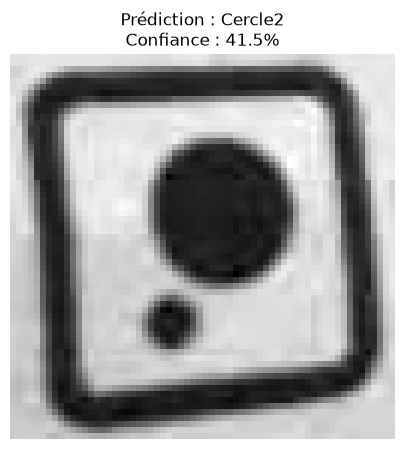

('Cercle2', np.float64(41.510463058293816))

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Liste de vos 8 classes (à adapter selon vos indices exacts)
NOMS_CLASSES = ["Cercle2", "Cercle5", "Diamant2", "Diamant5", "Hexagone2", "Hexagone5", "Triangle2", "Triangle5"]

def predire_image_brute(chemin_image, modele, mean_features, std_features):
    """
    Prend une image brute, extrait automatiquement la ROI via le pipeline OpenCV,
    puis effectue la prédiction avec le réseau de neurones from scratch.
    """
    # 1. Chargement de l'image en niveaux de gris
    image_gray = cv2.imread(chemin_image, cv2.IMREAD_GRAYSCALE)
    if image_gray is None:
        print("Erreur : Impossible de charger l'image. Vérifiez le chemin.")
        return None
        
    h_img, w_img = image_gray.shape

    # 2. Pipeline de détection ROI (identique à votre préparation de dataset)
    blurred = cv2.GaussianBlur(image_gray, (3, 3), 0)
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 3
    )
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)

    cnts, hierarchy = cv2.findContours(thresh.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    candidats_marqueurs = []
    best_box = None

    if hierarchy is not None and len(cnts) > 0:
        hier = hierarchy[0]
        for i, c in enumerate(cnts):
            x, y, w, h = cv2.boundingRect(c)
            box_area = float(w * h)

            # Filtres géométriques stricts
            if x <= 1 or y <= 1 or (x + w) >= (w_img - 1) or (y + h) >= (h_img - 1):
                continue
            if w < 20 or h < 20 or w > (w_img * 0.9) or h > (h_img * 0.9):
                continue

            ar = w / float(h)
            if not (0.82 <= ar <= 1.22):
                continue

            # Vérification de l'anneau creux (structure interne)
            child_idx = hier[i][2]
            if child_idx == -1:
                continue

            cx, cy, cw, ch = cv2.boundingRect(cnts[child_idx])
            ratio_trou = float(cw * ch) / box_area
            if not (0.35 <= ratio_trou <= 0.82):
                continue

            # Comptage des motifs et contraste
            nb_motifs = 0
            grandchild_idx = hier[child_idx][2]
            while grandchild_idx != -1:
                gc_area = cv2.contourArea(cnts[grandchild_idx])
                if gc_area > 8:
                    nb_motifs += 1
                grandchild_idx = hier[grandchild_idx][0]

            sub_roi = image_gray[y:y+h, x:x+w]
            std_dev = np.std(sub_roi)
            if std_dev < 18:
                continue

            candidats_marqueurs.append({
                'box': (x, y, w, h),
                'nb_motifs': nb_motifs,
                'std': std_dev
            })

    # Tri et sélection du meilleur candidat
    if len(candidats_marqueurs) > 0:
        candidats_marqueurs.sort(key=lambda elem: (elem['nb_motifs'] * 100) + elem['std'], reverse=True)
        best_box = candidats_marqueurs[0]['box']
        nb_motifs_val = candidats_marqueurs[0]['nb_motifs']
    else:
        nb_motifs_val = 0.0

    # Découpage de la ROI (ou repli centré si non trouvée)
    if best_box is not None:
        x, y, w, h = best_box
        pad = 1
        x1, y1 = max(0, x - pad), max(0, y - pad)
        x2, y2 = min(w_img, x + w + pad), min(h_img, y + h + pad)
        roi = image_gray[y1:y2, x1:x2]
        print("[INFO] Marqueurs détectés avec succès par le pipeline ROI !")
    else:
        margin_w = int(w_img * 0.15)
        margin_h = int(h_img * 0.15)
        roi = image_gray[margin_h:h_img - margin_h, margin_w:w_img - margin_w]
        print("[AVERTISSEMENT] Contour exact non trouvé, application du repli de secours centré.")

    # 3. Redimensionnement standard (64x64)
    roi_resized = cv2.resize(roi, (64, 64))

    # 4. Calcul des caractéristiques pour l'inférence
    std_dev_val = np.std(roi_resized)

    # 5. Aplatissement et Normalisation (identiques à l'entraînement)
    pixels_norm = roi_resized.flatten() / 255.0
    features_norm = ([nb_motifs_val, std_dev_val] - mean_features) / (std_features + 1e-8)
    
    # Vecteur d'entrée final (1, 4098)
    X_new = np.hstack((pixels_norm, features_norm)).reshape(1, -1)

    # 6. Prédiction du modèle
    probabilites = modele.forward(X_new)
    index_prediction = np.argmax(probabilites, axis=1)[0]
    confiance = probabilites[0][index_prediction] * 100
    nom_prediction = NOMS_CLASSES[index_prediction]

    # 7. Affichage du résultat et de la ROI extraite
    plt.figure(figsize=(5, 5))
    plt.imshow(roi_resized, cmap="gray")
    plt.title(f"Prédiction : {nom_prediction}\nConfiance : {confiance:.1f}%")
    plt.axis("off")
    plt.show()

    return nom_prediction, confiance

# --- EXEMPLE D'UTILISATION ---
chemin_photo = "EnsembleA/Cercles/Cercle2/269_Cercle2.jpg"
predire_image_brute(chemin_photo, modele_final, moyenne_finale, ecart_type_final)